# Wien's Law, Symbolic and Numeric, and the 502 nm Wave

> *The Sun's surface is 5780 K and its intensity peaks at 502 nm. If the temperature rose
> to 7000 K, where would the blackbody spectrum peak?* Options: 608, 414, 502, 580, 700 nm.

**Problem source (IEEE style):**

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.wien_wave_502 import (
    wien_root_symbolic, wien_condition_symbolic, wien_constant, scale_peak_symbolic, scale_peak,
    peak_numpy, peak_torch, options_table, wave_parameters, field, polarizer_projection,
    unpolarized_through_polarizer, ellipse_polygon, shoelace_area, ellipse_area_symbolic, IEEE_CITATION,
)
from dgs.blackbody import planck_radiance, hydrogen_series_wavelengths
print("[1]", IEEE_CITATION)

[1] R. D. Knight, "Foundations of Modern Physics," ch. 37 in Physics for Scientists and Engineers: A Strategic Approach with Modern Physics, 5th ed. Hoboken, NJ, USA: Pearson, 2022.


| § | method | result |
|---|---|---|
| 1 | **SymPy**: derive Wien's constant from Planck's law (Lambert W) | $b = \lambda_\max T = 2.898\times10^{-3}$ m·K |
| 2 | SymPy ratio + **pandas** loop over the options | **414 nm** |
| 3 | **numpy** grid search + **torch** autograd Newton method | same peak, independently |
| 4 | continuous vs. discrete spectra (the next quiz question) | Planck curve vs. hydrogen lines |
| 5 | the 502 nm wave: $k$, $f$, photon energy, field amplitude | $E_0 \approx 1$ kV/m in sunlight |
| 6 | **polarization**: projection through a polarizer, unpolarized sunlight | Malus $\cos^2\theta$; ½ |
| 7 | **polygon** representation of the polarization ellipse | shoelace area → $\pi E_{x0}E_{y0}\lvert\sin\delta\rvert$ |

# 1. Where does Wien's law come from? (SymPy)

Planck's spectral radiance per unit wavelength is
$B_\lambda = \dfrac{2hc^2}{\lambda^5}\dfrac{1}{e^{hc/\lambda kT} - 1}$. Set $dB_\lambda/d\lambda = 0$ and
substitute $x = hc/(\lambda kT)$. The condition no longer contains $T$ or $\lambda$
separately, which is *why* $\lambda_\max T$ is a constant:

In [2]:
cond, x = wien_condition_symbolic()
display(Math(r"\frac{dB_\lambda}{d\lambda} = 0 \;\Longleftrightarrow\; " + sp.latex(cond) + " = 0"))
root, _ = wien_root_symbolic()
display(Math(r"x = " + sp.latex(root) + r" \approx " + sp.latex(sp.N(root, 8))))
display(Math(r"b = \lambda_\max T = \frac{hc}{kx} = " + f"{wien_constant():.6e}" + r"\ \text{m K}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

SymPy solves $x = 5(1 - e^{-x})$ exactly with the **Lambert W function** (the inverse of
$we^w$). It's a transcendental equation, so there's no elementary closed form.

# 2. The answer: a ratio, then test every option

Same $b$ at both temperatures, so $\lambda_1T_1 = \lambda_2T_2$:

In [3]:
l2, (l1, T1, T2) = scale_peak_symbolic()
display(Math(r"\lambda_2 = " + sp.latex(l2) + r" = 502\,\text{nm}\times\frac{5780}{7000} = " + f"{scale_peak(502, 5780, 7000):.1f}" + r"\ \text{nm}"))
df, target = options_table()
df

<IPython.core.display.Math object>

,option (nm),lambda*T (m K),error vs 502*5780/7000 (%),bluer than 502 nm?,verdict
0,608,0.004256,46.679717,False,wrong
1,414,0.002898,-0.122693,True,correct
2,502,0.003514,21.107266,False,wrong
3,580,0.004060,39.924730,False,wrong
4,700,0.004900,68.874674,False,wrong


**Only 414 nm works.** Quick filter before computing: a hotter object peaks **bluer** (shorter
wavelength), so 502 nm and above are out immediately. That's the "bluer than 502 nm?" column.

# 3. Check numerically: numpy and torch

- **numpy**: evaluate $B_\lambda$ on a 200,001-point grid and take the argmax.
- **torch**: Newton's method on $g(\lambda) = d\ln B/d\lambda$, with $g$ and $g'$ computed by **autograd**. No hand-derived derivatives, which makes it a fully independent check of the SymPy result.

  T (K)   b/T (nm)  numpy argmax  torch Newton  device


   5780    501.345       501.346       501.345  cuda
   7000    413.967       413.969       413.967  cuda


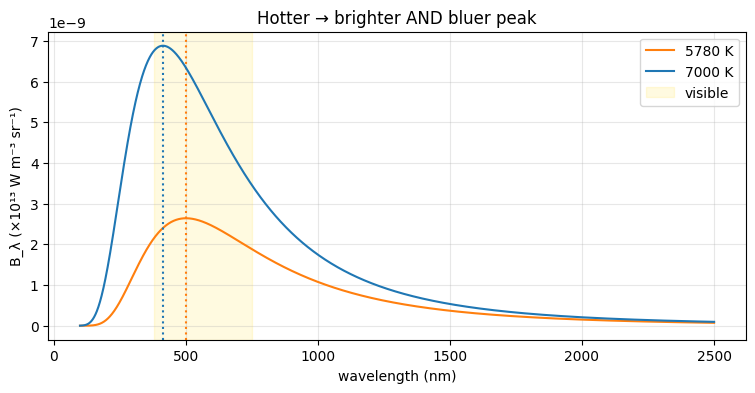

In [4]:
print(f"{'T (K)':>7s} {'b/T (nm)':>10s} {'numpy argmax':>13s} {'torch Newton':>13s}  device")
for T in (5780.0, 7000.0):
    tp, dev = peak_torch(T)
    print(f"{T:7.0f} {wien_constant()/T*1e9:10.3f} {peak_numpy(T):13.3f} {tp:13.3f}  {dev}")
lam = np.linspace(100, 2500, 2000)
fig, ax = plt.subplots(figsize=(9, 4))
for T, col in ((5780, "C1"), (7000, "C0")):
    B = planck_radiance(lam, T); ax.plot(lam, B/1e13, col, label=f"{T} K")
    ax.axvline(wien_constant()/T*1e9, color=col, ls=":")
ax.axvspan(380, 750, color="gold", alpha=0.12, label="visible")
ax.set(xlabel="wavelength (nm)", ylabel="B_λ (×10¹³ W m⁻³ sr⁻¹)", title="Hotter → brighter AND bluer peak")
ax.legend(); ax.grid(alpha=0.3); plt.show()

The exact Planck peak at 5780 K is 501.3 nm. The problem's "502 nm" is rounded,
which is why the table shows 414 nm differing from 414.5 nm by 0.1%.

**Jacobian subtlety:** the peak of $B_\nu$ (per *frequency*) for the Sun is near 883 nm, not 502 nm.
Spectra per unit wavelength and per unit frequency are densities in different variables, so
they peak in different places. The question says "per unit wavelength", so $b/T$ is correct.

# 4. Continuous vs. discrete spectra (the next question in the round)

A **blackbody** (hot, dense matter) emits a **continuous** spectrum: every wavelength,
shaped by temperature alone. A **gas discharge tube** (isolated atoms) emits only at
**discrete** wavelengths, the transitions between energy levels. Hydrogen's visible
(Balmer) lines come from $1/\lambda = R_\infty(1/2^2 - 1/n^2)$.

*Trap in the options:* **cathode rays are electrons**, not electromagnetic radiation,
so "the intensity spectrum from cathode rays" isn't an EM spectrum at all.

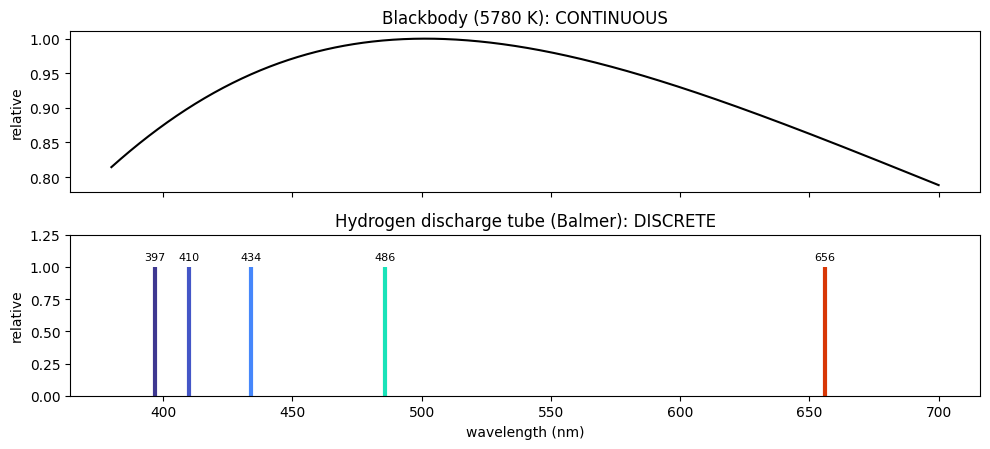

,n_upper,n_lower,wavelength_nm,energy_eV
0,3,2,656.11,1.89
1,4,2,486.01,2.55
2,5,2,433.94,2.86
3,6,2,410.07,3.02
4,7,2,396.91,3.12


In [5]:
lines = hydrogen_series_wavelengths([3, 4, 5, 6, 7], 2)
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
lam = np.linspace(380, 700, 800); B = planck_radiance(lam, 5780)
axes[0].plot(lam, B/B.max(), "k"); axes[0].set(ylabel="relative", title="Blackbody (5780 K): CONTINUOUS")
for ln in lines:
    axes[1].vlines(ln["wavelength_nm"], 0, 1, color=plt.cm.turbo((ln["wavelength_nm"]-380)/320), lw=3)
    axes[1].text(ln["wavelength_nm"], 1.05, f"{ln['wavelength_nm']:.0f}", ha="center", fontsize=8)
axes[1].set(ylim=(0, 1.25), xlabel="wavelength (nm)", ylabel="relative", title="Hydrogen discharge tube (Balmer): DISCRETE")
plt.tight_layout(); plt.show()
pd.DataFrame(lines)[["n_upper", "n_lower", "wavelength_nm", "energy_eV"]].round(2)

# 5. The 502 nm wave itself

A light wave polarized along $\hat x$ and travelling along $z$:
$\;\vec E(z, t) = E_0\cos(kz - \omega t)\,\hat x$, with $k = 2\pi/\lambda$ and $\omega = 2\pi c/\lambda$.
Its amplitude follows from the irradiance, $I = \tfrac12 c\varepsilon_0E_0^2$. *Assumption:* all
1361 W/m² of sunlight at Earth (the solar constant, really spread over the whole spectrum)
treated as if it were at 502 nm, to get the size scale.

k (rad/m)                              1.252e+07
frequency (THz)                        597.2
omega (rad/s)                          3.752e+15
period (fs)                            1.674
photon energy (eV)                     2.47
E0 (V/m)                               1013
B0 (uT)                                3.378
photons / (m^2 s) if all at this lam   3.439e+21


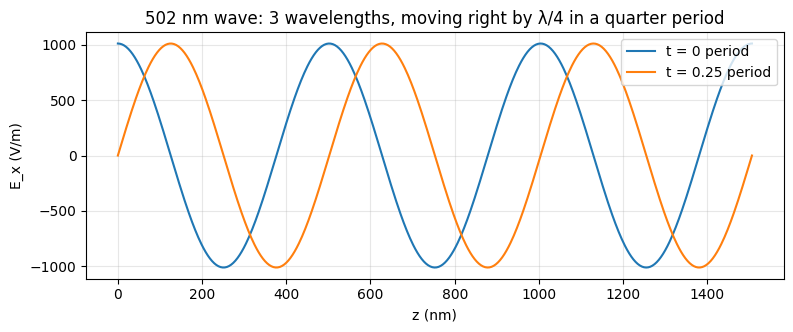

In [6]:
for k_, v in wave_parameters().items():
    print(f"{k_:38s} {v:.4g}")
lam_m = 502e-9; z = np.linspace(0, 3*lam_m, 600); E0 = wave_parameters()["E0 (V/m)"]
fig, ax = plt.subplots(figsize=(9, 3.2))
for frac, col in ((0, "C0"), (0.25, "C1")):
    ax.plot(z*1e9, field(z, frac*lam_m/299792458.0, E0=E0), col, label=f"t = {frac:g} period")
ax.set(xlabel="z (nm)", ylabel="E_x (V/m)", title="502 nm wave: 3 wavelengths, moving right by λ/4 in a quarter period")
ax.legend(); ax.grid(alpha=0.3); plt.show()

# 6. Polarization and projection

A polarizer keeps only the field component along its axis. That's an **inner product**
(projection) of the field's Jones vector onto the axis, so the amplitude becomes $E_0\cos\theta$
and the intensity $I_0\cos^2\theta$ (**Malus's law**). Computed with `dgs.jones_calculus`:

In [7]:
th = np.arange(0, 181, 15)
rows = [{"polarizer angle (deg)": t, "amplitude / E0": polarizer_projection(0, t)[0],
         "intensity / I0": polarizer_projection(0, t)[1], "cos² θ": np.cos(np.radians(t))**2} for t in th]
display(pd.DataFrame(rows).round(4))
print(f"unpolarized input (random angles, Monte Carlo): transmitted fraction = {unpolarized_through_polarizer():.4f}  (→ 1/2)")

,polarizer angle (deg),amplitude / E0,intensity / I0,cos² θ
0,0,1.0000,1.000,1.000
1,15,0.9659,0.933,0.933
2,30,0.8660,0.750,0.750
3,45,0.7071,0.500,0.500
4,60,0.5000,0.250,0.250
5,75,0.2588,0.067,0.067
6,90,0.0000,0.000,0.000
7,105,0.2588,0.067,0.067
8,120,0.5000,0.250,0.250
9,135,0.7071,0.500,0.500


unpolarized input (random angles, Monte Carlo): transmitted fraction = 0.4989  (→ 1/2)


**Sunlight is unpolarized.** Its polarization direction changes randomly from moment to
moment, so a polarizer passes $\langle\cos^2\theta\rangle = \tfrac12$ of it. That's why polarized
sunglasses halve the glare, and why light scattered from the sky (Rayleigh scattering at
90°) *is* partly polarized: scattering picks out a direction.

# 7. A polygon representation of polarization

With $E_x = E_{x0}\cos\omega t$ and $E_y = E_{y0}\cos(\omega t + \delta)$, the tip of $\vec E$ traces an
ellipse. Sample it at $N$ instants and you get an $N$-sided **polygon**. The shoelace formula
gives its area, which converges to the exact ellipse area from Green's theorem (SymPy).
The area is zero for linear polarization and largest for circular polarization.

<IPython.core.display.Math object>

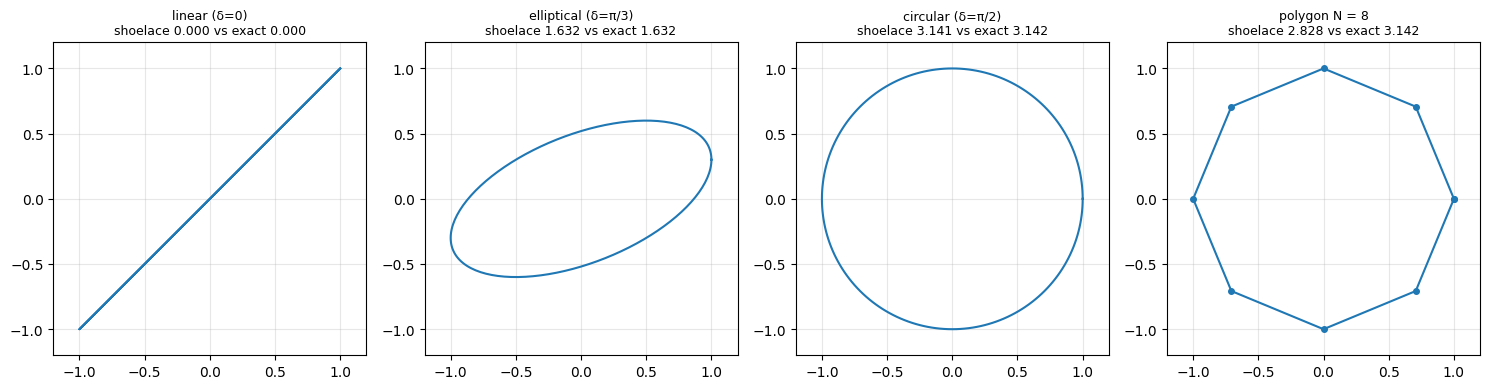

N =    4: polygon area 2.000000   (π = 3.141593)
N =    8: polygon area 2.828427   (π = 3.141593)
N =   16: polygon area 3.061467   (π = 3.141593)
N =   64: polygon area 3.136548   (π = 3.141593)
N =  256: polygon area 3.141277   (π = 3.141593)


In [8]:
area = ellipse_area_symbolic()
display(Math(r"A_\text{ellipse} = \tfrac12\oint (E_x\,dE_y - E_y\,dE_x) = " + sp.latex(area)))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (name, a, b, d) in zip(axes, (("linear (δ=0)", 1, 1, 0.0), ("elliptical (δ=π/3)", 1, 0.6, np.pi/3),
                                       ("circular (δ=π/2)", 1, 1, np.pi/2), ("polygon N = 8", 1, 1, np.pi/2))):
    n = 8 if "N = 8" in name else 200
    P = ellipse_polygon(a, b, d, n); Pc = np.vstack([P, P[:1]])
    ax.plot(Pc[:, 0], Pc[:, 1], "o-" if n == 8 else "-", ms=4)
    ax.set_title(f"{name}\nshoelace {shoelace_area(P):.3f} vs exact {np.pi*a*b*abs(np.sin(d)):.3f}", fontsize=9)
    ax.set_aspect("equal"); ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for n in (4, 8, 16, 64, 256):
    print(f"N = {n:4d}: polygon area {shoelace_area(ellipse_polygon(1, 1, np.pi/2, n)):.6f}   (π = {np.pi:.6f})")

## Exercises
1. Use the torch Newton solver to find the peak of $B_\nu$ (per frequency) and confirm it is $c/\lambda \approx 883$ nm, not 502 nm, for the Sun.
2. At what temperature does a blackbody peak at 656 nm (hydrogen's red Balmer line)?
3. Two crossed polarizers pass nothing. Insert a third at 45° between them. What fraction passes now?
4. Show the polygon area of a regular N-gon inscribed in the unit circle is $\tfrac N2\sin(2\pi/N)$, and take the limit $N\to\infty$ with SymPy.